# **Seaborn & Pandas Plot 기본기 익히기**

먼저 seaborn으로 시각화를 하고, 그 다음 같은 데이터를 pandas plot으로 그려보는 실습을 한다.


## **한글 폰트 설치**

In [1]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

## Wide-form과 Long-form

- **Long-form**: 분류 값이 컬럼 이름이 아니라, **하나의 컬럼 안에 값으로** 들어있는 세로로 긴 형태. seaborn이 선호한다 (특히 `hue` 사용 시).
- **Wide-form**: 분류 값들이 **컬럼 이름으로 옆으로 나열**되어있는 가로로 넓은 형태. pandas plot이 선호한다.

| pandas 명령어 | 의미 |
|---|---|
| `df.pivot(index=, columns=, values=)` | long-form → wide-form |
| `df.melt(id_vars=, var_name=, value_name=)` | wide-form → long-form |


## **데이터 살펴보기**

In [2]:
df = pd.read_csv("cafe.csv")
df.head()

,월,메뉴,판매량
0,1월,아메리카노,50
1,1월,라떼,40
2,1월,에이드,15
3,1월,스무디,10
4,2월,아메리카노,55


## **1. Seaborn**

### **1. 선그래프**
| 명령어 | 의미 |
|---|---|
| `sns.lineplot(data=df, x=, y=)` | 같은 x값에 여러 행이 있으면 자동으로 평균+신뢰구간을 그림 |
| `hue=` | 범주별로 선을 나눠서 그리기 |
| `style=` | 범주별로 스타일 변경하기 |
|`markers=` | 데이터에 마커를 추가한다. |


**Q1. 월별 판매량을 선 그래프로 그려보자.**

- 제목 : 월별 판매량

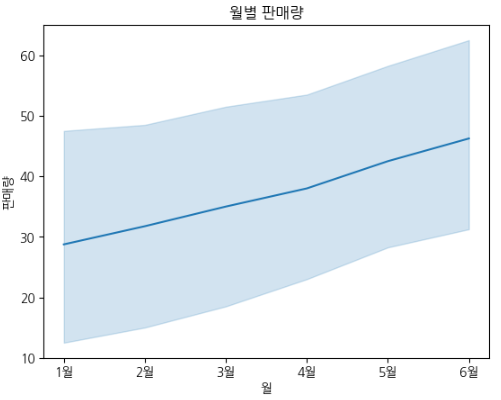

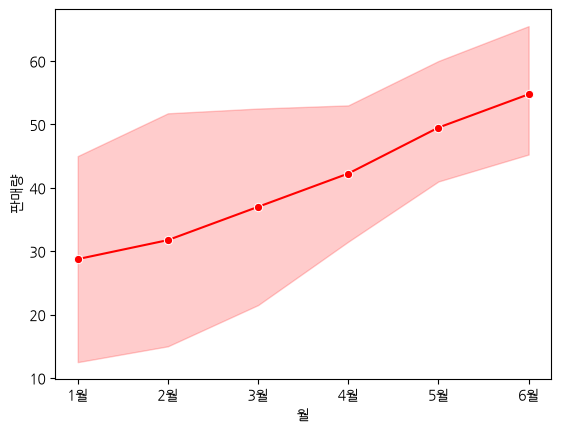

In [5]:
# code here
sns.lineplot(df, x='월', y='판매량', marker='o', c='red')
plt.show()

**Q2. 메뉴별로 선을 구분해보자.**
- 제목 : '메뉴별 월간 판매량'

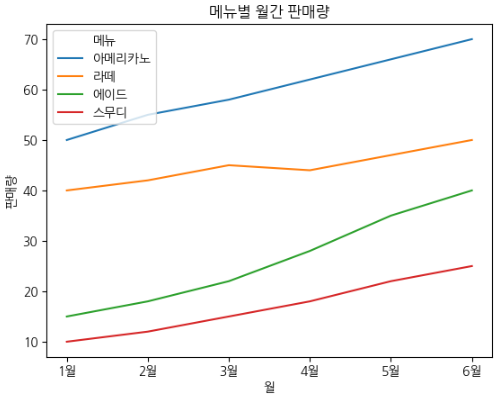

In [2]:
# code here

**Q3. 메뉴별로 스타일을 변경해보자.**
- 그리고 markers 옵션도 켜서 데이터별 위치를 명확히 시각화하자.

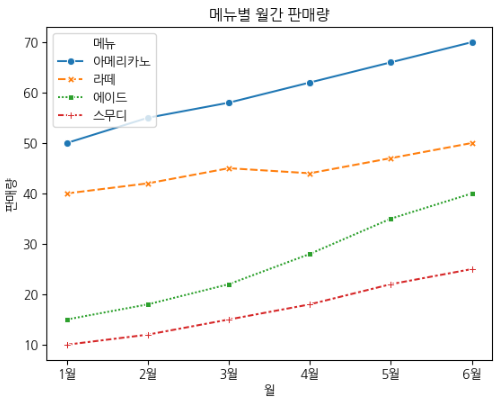

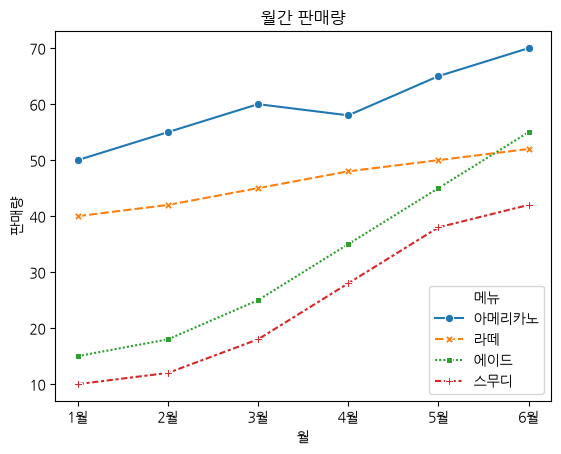

In [9]:
plt.title('월간 판매량')

# seaborn : hue / style
sns.lineplot(df, x='월', y='판매량', marker='o', hue='메뉴', style='메뉴', markers=True)

plt.show()

### **2. 막대그래프**

| 명령어 / 옵션 | 의미 |
|---|---|
| `sns.barplot(data=df, x=, y=)` | 기본적으로 값을 **평균**내서(estimator='mean') 막대로 그리고, 에러바도 표시 |
| `sns.countplot(data=df, x=, )` | 값이 등장한 개수를 막대로 그린다. |
| `estimator=` | 통계 방식 변경 (`'mean'`(기본), `'median'`, `'sum'`) |
| `hue=` | 범주별로 막대를 나눠서 그리기 |


**Q1. 메뉴별 판매량을 나타내는 막대 그래프를 그려보자.**
- 제목 : 메뉴별 평균 판매량

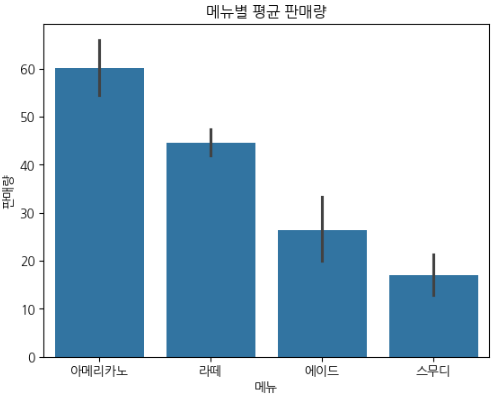

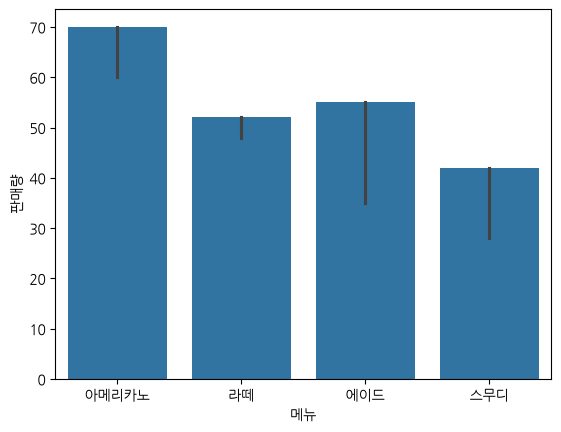

In [13]:
# code here

# barplot : estimator
sns.barplot(df, x=df['메뉴'], y=df['판매량'], estimator="max")
plt.show()

**Q2. 통계 방식 바꾸기**

같은 그래프를 중앙값을 표현하도록 바꿔보자.
- 제목 : 메뉴별 판매량 중앙값


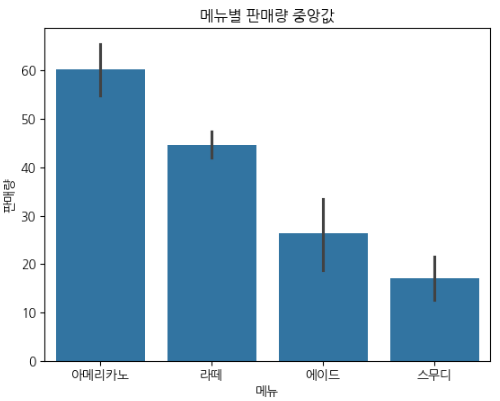

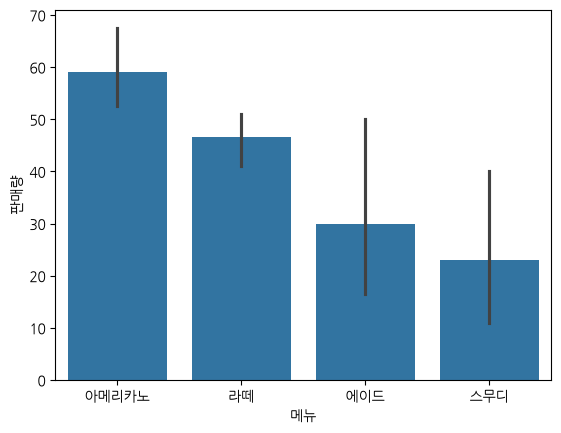

In [16]:
sns.barplot(df, x=df['메뉴'], y=df['판매량'], estimator="median")
plt.show()

**Q3. 월별 판매량을 메뉴별로 구분하기**

-제목 : '메뉴별 월간 판매량'


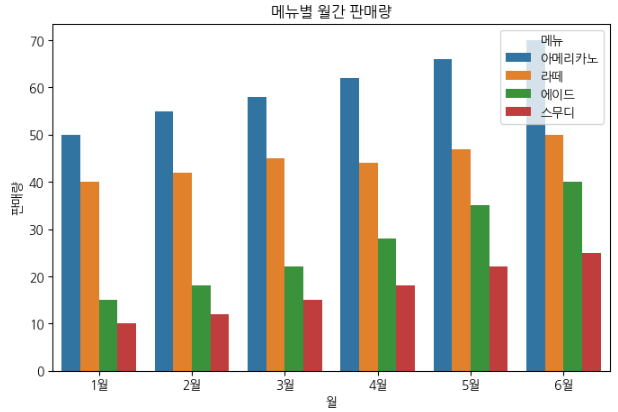

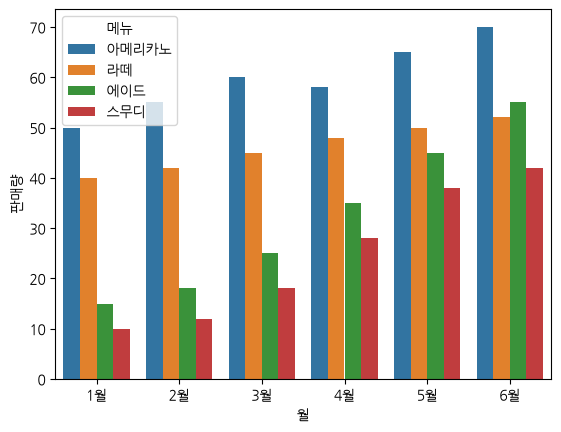

In [20]:
sns.barplot(df, x=df['월'], y=df['판매량'], hue='메뉴', estimator='sum')
plt.show()

**Q4. 메뉴별 데이터의 수를 시각화해보자.**

- 제목 : '메뉴별 결제 수'


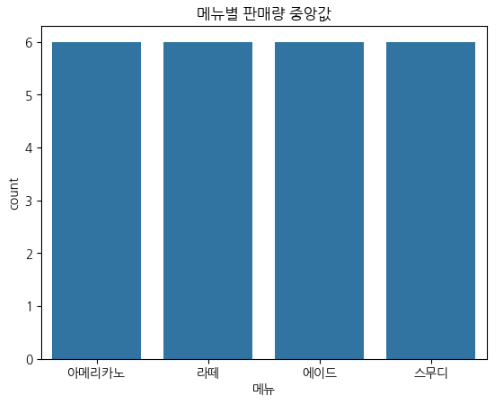

<Axes: xlabel='메뉴', ylabel='count'>

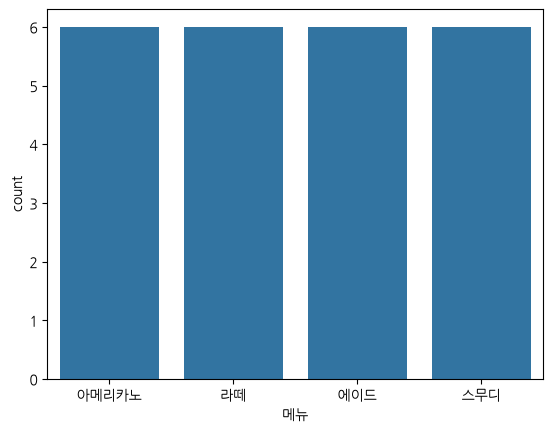

In [22]:
sns.countplot(df, x='메뉴')

### **3. 산점도 그래프**

| 명령어 | 의미 |
|---|---|
| `sns.scatterplot(data=df, x=, y=, hue=)` | 범주별로 색을 구분한 산점도 (long-form) |
| `sns.pairplot(df)` | 숫자형 컬럼 **모든 쌍**의 관계를 한 번에 (wide-form 필요!) |


**Q1. 월간 판매량을 산점도 그래프로 시각화한다.**

- 제목 : '월간 판매량'

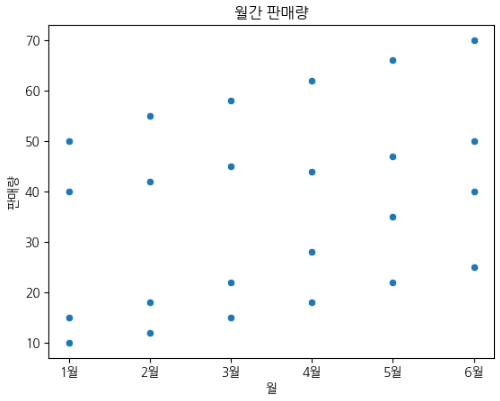

In [8]:
# code here

**Q2. 메뉴별로 색을 구분해보자.**
- 제목 : '메뉴별 월간 판매량'




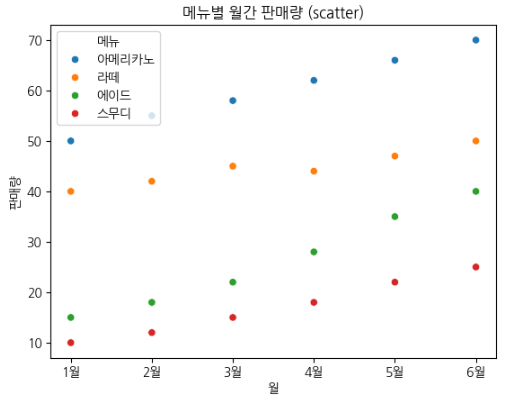

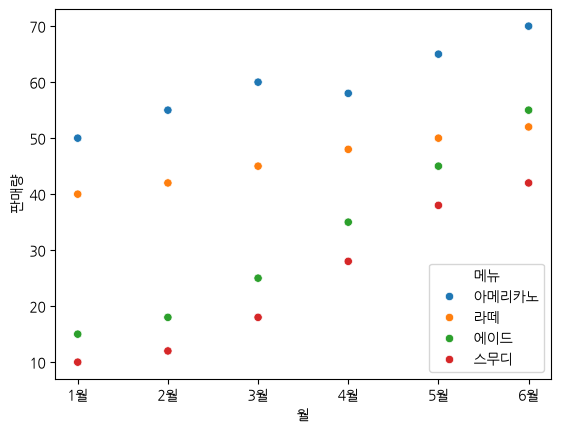

In [27]:
sns.scatterplot(df, x='월', y='판매량', hue='메뉴')
plt.show()

**Q3. pairplot 그리기**

pairplot은 기본적으로 각 메뉴를 별개의 컬럼으로 취급해야 하므로, wide-form의 데이터가 필요하다.

- df를 wide_form으로 만든 뒤, pairplot을 그려라.

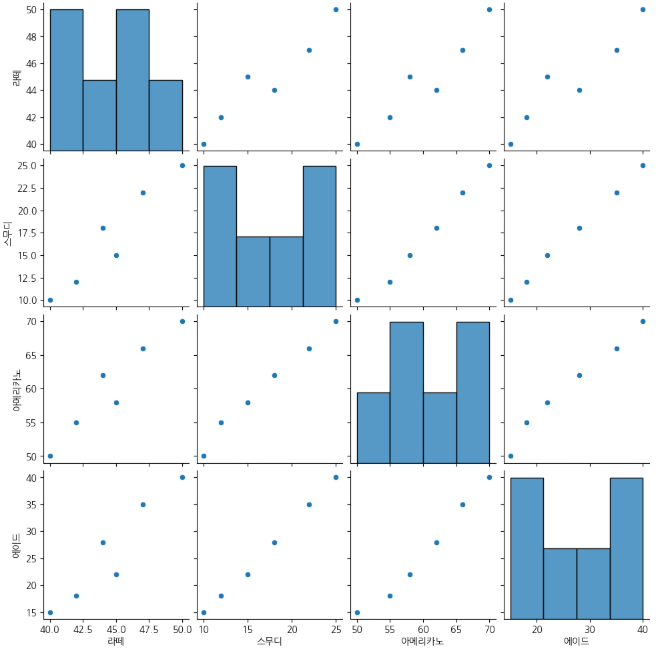

In [33]:
# longform -> wideform
# pivot
wide_df = df.pivot(index='월', columns='메뉴', values='판매량').reset_index()
wide_df

메뉴,월,라떼,스무디,아메리카노,에이드
0,1월,40,10,50,15
1,2월,42,12,55,18
2,3월,45,18,60,25
3,4월,48,28,58,35
4,5월,50,38,65,45
5,6월,52,42,70,55


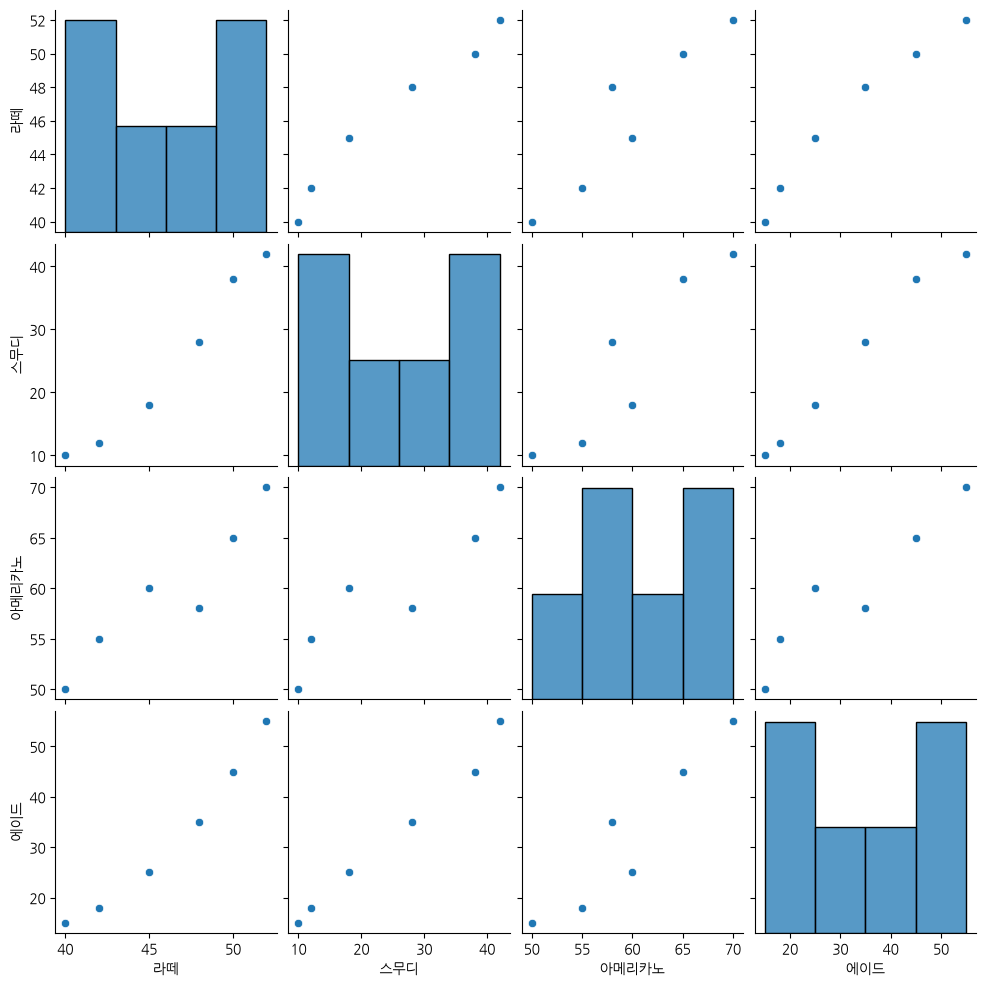

In [35]:
sns.pairplot(wide_df)
plt.show()

### **4. 히스토그램**

| 명령어 / 옵션 | 의미 |
|---|---|
| `sns.histplot(data=df, x=)` | 기본 히스토그램 |
| `kde=True` | 부드러운 밀도 곡선을 겹쳐 그리기 |
| `hue=`, `multiple=''` | 범주별 히스토그램을 한번에 여러개 그리기 |


**Q1. 기본 히스토그램 그리기**
- 제목 : '전체 판매량 분포'

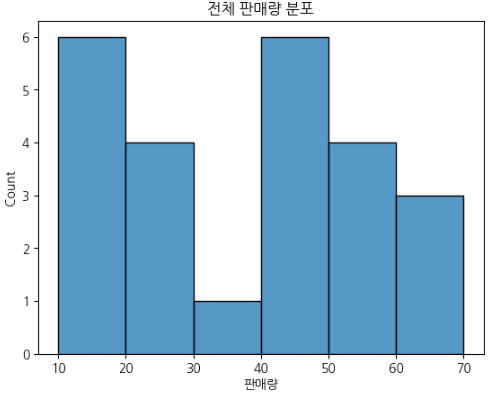

<Axes: xlabel='판매량', ylabel='Count'>

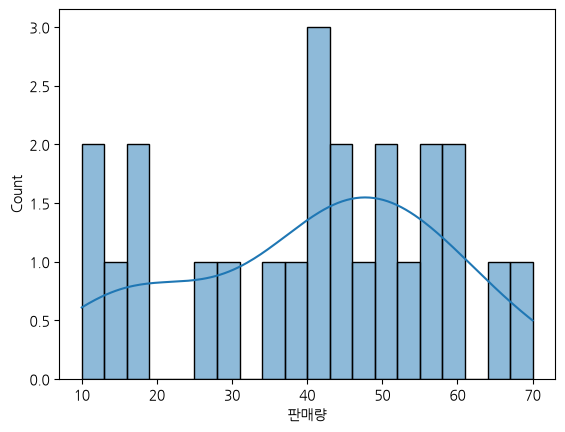

In [ ]:
# histplot : kde!
sns.histplot(df, x='판매량', bins=20 ,kde=True)

**Q2. 밀도 곡선 그리기**
- kde 선을 같이 그려본다.
- bins도 10개로 늘려 촘촘하게 분포를 확인한다.

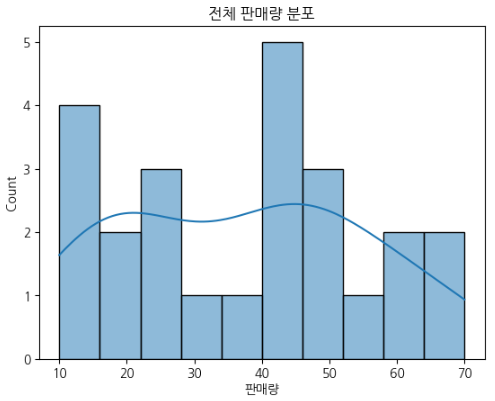

In [12]:
# code here

**Q3. 메뉴별 분포 쌓아서 비교하기**

메뉴별 분포를 겹쳐서 시각화한다.

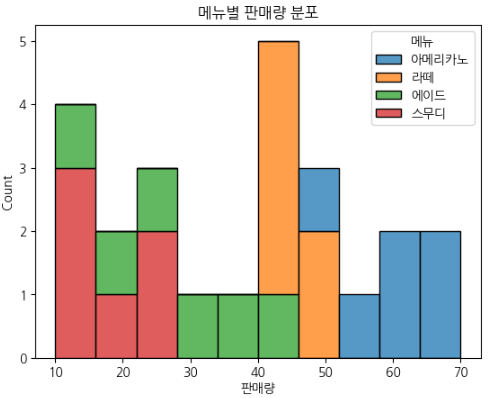

<Axes: xlabel='판매량', ylabel='Count'>

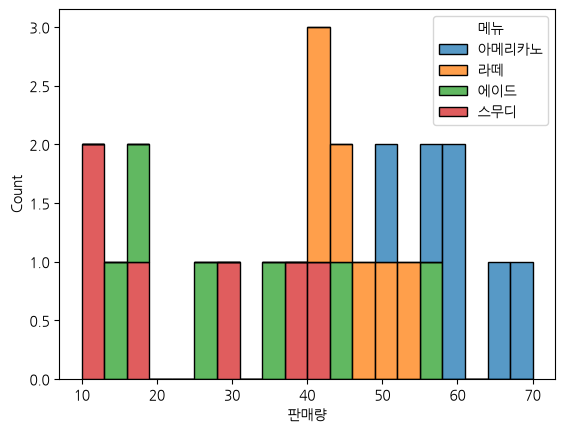

In [48]:
# multiple 옵션..
sns.histplot(df, x='판매량', hue='메뉴', bins=20 , multiple='stack')

**Q3. 메뉴별 분포 개별적으로 비교하기**

메뉴별 분포를 서로 떨어뜨려놓아 시각화한다.

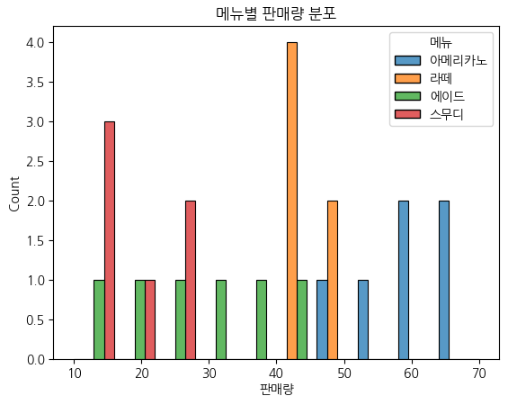

In [ ]:
sns.histplot()

### **5. 박스플롯**

| 명령어 | 의미 |
|---|---|
| `sns.boxplot(data=df, x=, y=)` | x 컬럼의 각 카테고리별로 y의 분포를 박스로 비교 (long-form) |


**Q1. 메뉴별 판매량의 분포 비교하기**

- 제목 : '메뉴별 판매량 분포'

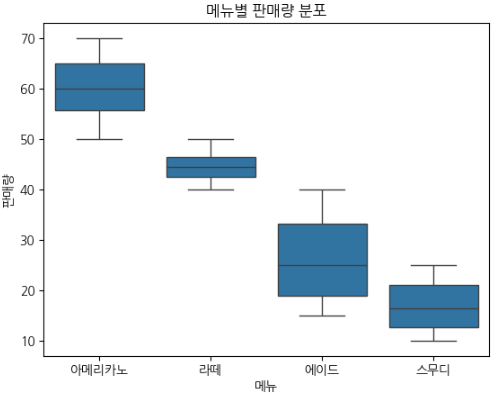

<Axes: xlabel='메뉴', ylabel='판매량'>

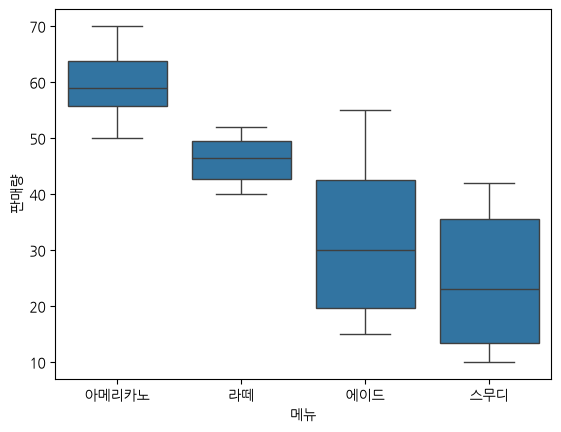

In [49]:
sns.boxplot(df, x='메뉴', y='판매량')

## **2. Pandas Plot**


### **1. wide-form**

**Q1. df 데이터를 wide-form으로 변환한다.**

- 각 메뉴를 별개의 컬럼으로 취급하도록 한다.

In [25]:
# code here

### **1. 선그래프**


| 명령어 | 의미 |
|---|---|
| `df.plot(x=)` | wide-form DataFrame에서 지정한 열을 x축으로, 나머지 숫자형 열들을 각각 선으로 그리기 |

**Q1. pandas plot과 wide_df를 활용하여 메뉴별 월간 판매량의 선 그래프를 그린다.**

- 제목 : '메뉴별 판매량 추이'
- pandas plot은 제목을 그래프를 그리는 코드 이후에 작성해야 한다.

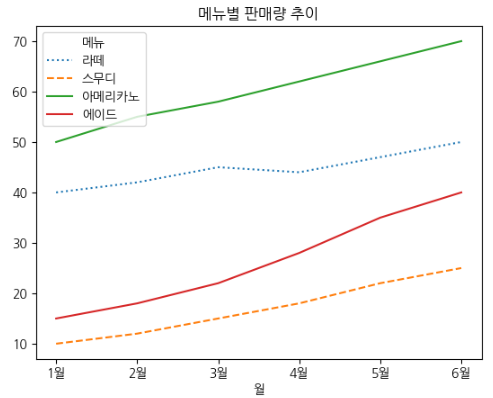

In [17]:
# code here

### **2. 막대그래프**

| 명령어 | 의미 |
|---|---|
| `df.plot(kind='bar', x=)` | wide-form에서 지정한 열을 x축(카테고리)으로, 나머지 숫자형 열들을 막대로 나란히 그리기 |

**Q1. 메뉴별 월간 판매량을 막대 그래프로 시각화한다.**

- 제목 : '메뉴별 월간 판매량'

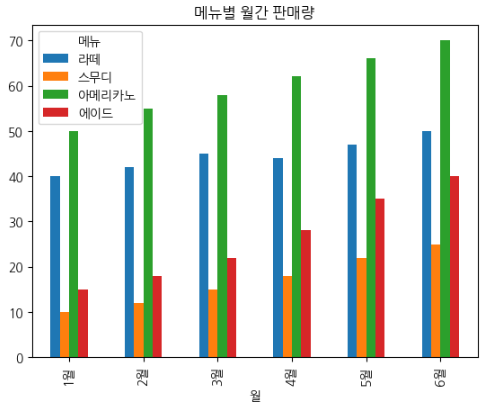

In [18]:
# code here

### **3. 산점도그래프**

| 명령어 | 의미 |
|---|---|
| `df.plot(kind='scatter', x=, y=)` | 두 숫자형 열 사이의 산점도 (x, y는 각각 열 하나씩만 가능, 카테고리별 색 구분 불가) |

**Q1. 월별 라떼 판매량을 산점도 그래프로 시각화한다.**
- 제목 : 월별 라떼 판매량

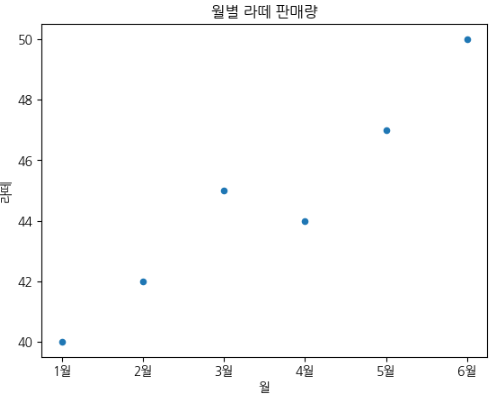

In [19]:
# code here

**Q2. 메뉴별 월간 판매량 산점도 그래프 그리기**

- pandas plot은 hue 카테고리별로 색을 구분하는 기능이 없다.
- 반복문을 활용해서 한 군데에 그리기 위해서는 subplot (layout)에 대한 공부가 필요하다.

그렇기에, 그냥 wide_form 데이터를 long_form으로 변환시켜 seaborn으로 그리는것이 더 편한다.

- 데이터를 long_form으로 다시 변환하여 searborn으로 산점도 그래프를 그려라.


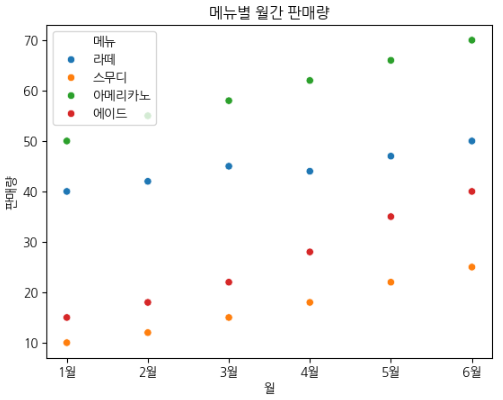

In [20]:
# code here

### **4. 히스토그램**

| 명령어 | 의미 |
|---|---|
| `df[[열1, 열2, ...]].plot(kind='hist', alpha=, bins=)` | 여러 숫자형 열의 히스토그램을 겹쳐서 그리기 |

**Q1. 여러 메뉴 컬럼을 겹쳐서 히스토그램 그리기**


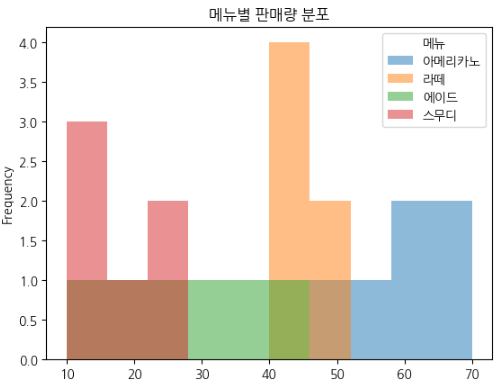

In [22]:
# code here

### **5. 박스플롯**

| 명령어 | 의미 |
|---|---|
| `df.plot(kind='box')` | wide-form의 각 숫자형 열마다 하나의 박스를 자동으로 그려서 비교 |

**Q1 메뉴별 월간 판매량을 박스플롯으로 시각화해보자.**


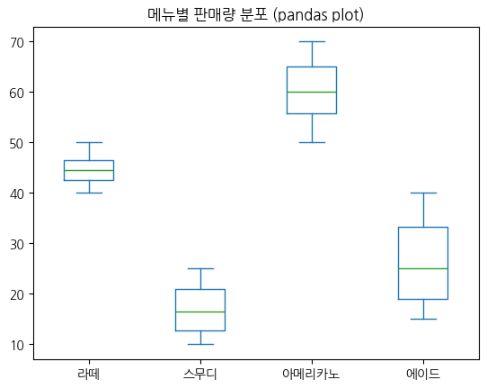

In [24]:
# code here